In this notebook, We'll investigate three important questions:
1. Can a Barabási–Albert model reproduce the degree distribution of our collaboration network?
2. Does the real network exhibit different structural properties from a configuration-model randomized network?
3. Do highly connected researchers tend to collaborate with other highly connected researchers?

# Generate and analyze a Barabási–Albert network

In [ ]:
# Install required packages
!pip install networkx pandas numpy matplotlib

In [ ]:
# Import libraries

import os
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

# Project directories
PROJECT_DIR = "/content/drive/MyDrive/NetworkScience/NSProject"

DATA_DIR = os.path.join(PROJECT_DIR, "data", "raw")
FIGURES_DIR = os.path.join(PROJECT_DIR, "figures", "B")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results", "B")

os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print("Directories configured!")

Mounted at /content/drive
Directories configured!


In [ ]:
# Load the cleaned networks

G_full = nx.read_graphml(
    os.path.join(RESULTS_DIR, "CA-GrQc_full.graphml")
)

G_lcc = nx.read_graphml(
    os.path.join(RESULTS_DIR, "CA-GrQc_LCC.graphml")
)

# Convert node identifiers back to integers
G_full = nx.relabel_nodes(
    G_full,
    {node: int(node) for node in G_full.nodes()}
)

G_lcc = nx.relabel_nodes(
    G_lcc,
    {node: int(node) for node in G_lcc.nodes()}
)

print("Full network:", G_full.number_of_nodes(), "nodes")
print("LCC:", G_lcc.number_of_nodes(), "nodes")
print("LCC edges:", G_lcc.number_of_edges())
print("LCC connected:", nx.is_connected(G_lcc))

Full network: 5242 nodes
LCC: 4158 nodes
LCC edges: 13422
LCC connected: True


In [ ]:
# Generate the BA network
# Real network parameters

N = G_lcc.number_of_nodes()

real_avg_degree = np.mean([
    degree for node, degree in G_lcc.degree()
])

# Choose BA parameter
m_ba = round(real_avg_degree / 2)

# Generate BA network
G_ba = nx.barabasi_albert_graph(
    n=N,
    m=m_ba,
    seed=SEED
)

# Display results
print("REAL NETWORK")
print("Nodes:", G_lcc.number_of_nodes())
print("Edges:", G_lcc.number_of_edges())
print("Average degree:", real_avg_degree)

print("\nBARABASI-ALBERT NETWORK")
print("Nodes:", G_ba.number_of_nodes())
print("Edges:", G_ba.number_of_edges())
print("Average degree:", np.mean([
    degree for node, degree in G_ba.degree()
]))

REAL NETWORK
Nodes: 4158
Edges: 13422
Average degree: 6.455988455988456

BARABASI-ALBERT NETWORK
Nodes: 4158
Edges: 12465
Average degree: 5.995670995670996


## Compare degree distributions

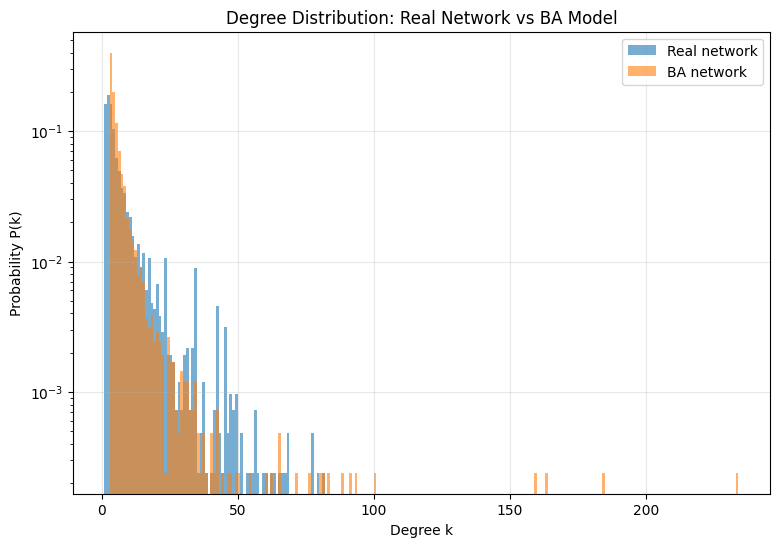

In [ ]:
# Extract degree sequences

degrees_real = [d for n, d in G_lcc.degree()]
degrees_ba = [d for n, d in G_ba.degree()]

# Plot degree distributions

plt.figure(figsize=(9, 6))

plt.hist(
    degrees_real,
    bins=range(1, max(degrees_real) + 2),
    density=True,
    alpha=0.6,
    label="Real network"
)

plt.hist(
    degrees_ba,
    bins=range(1, max(degrees_ba) + 2),
    density=True,
    alpha=0.6,
    label="BA network"
)

plt.yscale("log")
plt.xlabel("Degree k")
plt.ylabel("Probability P(k)")
plt.title("Degree Distribution: Real Network vs BA Model")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    os.path.join(FIGURES_DIR, "B2_degree_distribution_BA.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Compare clustering coefficients

In [ ]:
# Calculate average clustering coefficients

clustering_real = nx.average_clustering(G_lcc)
clustering_ba = nx.average_clustering(G_ba)

print("Real network clustering:", clustering_real)
print("BA network clustering:", clustering_ba)

Real network clustering: 0.5568782161697929
BA network clustering: 0.01114681373094464


## Compare average shortest path lengths

In [ ]:
# Calculate average shortest path lengths

path_real = nx.average_shortest_path_length(G_lcc)
path_ba = nx.average_shortest_path_length(G_ba)

print("Real network average path length:", path_real)
print("BA network average path length:", path_ba)

Real network average path length: 6.049380016182999
BA network average path length: 3.960411126396212


## Create a comparison table

In [ ]:
# Compare structural properties

ba_comparison = pd.DataFrame({
    "Metric": [
        "Number of nodes",
        "Number of edges",
        "Average degree",
        "Average clustering",
        "Average shortest path length"
    ],

    "Real network": [
        G_lcc.number_of_nodes(),
        G_lcc.number_of_edges(),
        np.mean(degrees_real),
        clustering_real,
        path_real
    ],

    "BA network": [
        G_ba.number_of_nodes(),
        G_ba.number_of_edges(),
        np.mean(degrees_ba),
        clustering_ba,
        path_ba
    ]
})

display(ba_comparison.round(4))

ba_comparison.to_csv(
    os.path.join(RESULTS_DIR, "B2_BA_comparison.csv"),
    index=False
)

,Metric,Real network,BA network
0,Number of nodes,4158.0000,4158.0000
1,Number of edges,13422.0000,12465.0000
2,Average degree,6.4560,5.9957
3,Average clustering,0.5569,0.0111
4,Average shortest path length,6.0494,3.9604


## Findings

The Barabási–Albert model reproduces the general idea of heterogeneous connectivity and hub formation, but it fails to reproduce the high clustering and local community structure of the real collaboration network.

This suggests that preferential attachment is not sufficient to explain the organization of scientific collaborations.

# Configuration Model Null

In [ ]:
# Extract the original node IDs and their degrees

original_nodes = list(G_lcc.nodes())

degree_sequence = [
    G_lcc.degree(node)
    for node in original_nodes
]

print("Number of nodes:", len(degree_sequence))
print("First 20 degrees:", degree_sequence[:20])

print("Sum of degrees:", sum(degree_sequence))
print("Number of edges:", G_lcc.number_of_edges())

print("Is the degree sum even?",
      sum(degree_sequence) % 2 == 0)

Number of nodes: 4158
First 20 degrees: [8, 5, 2, 5, 13, 10, 17, 3, 4, 8, 3, 34, 7, 10, 2, 17, 25, 8, 1, 21]
Sum of degrees: 26844
Number of edges: 13422
Is the degree sum even? True


In [ ]:
# Generate configuration-model network

G_config = nx.configuration_model(
    degree_sequence,
    seed=SEED
)

# Convert node IDs to the original researcher IDs
mapping = {
    i: original_nodes[i]
    for i in range(len(original_nodes))
}

G_config = nx.relabel_nodes(
    G_config,
    mapping
)

print("Configuration model generated!")
print("Number of nodes:", G_config.number_of_nodes())
print("Number of edges:", G_config.number_of_edges())
print("Is it a multigraph?", G_config.is_multigraph())
print("Number of self-loops:", nx.number_of_selfloops(G_config))

Configuration model generated!
Number of nodes: 4158
Number of edges: 13422
Is it a multigraph? True
Number of self-loops: 10


verify that degree sequence is preserved

In [ ]:
# Check every node's degree

degree_sequence_real = [
    G_lcc.degree(node)
    for node in original_nodes
]

degree_sequence_config = [
    G_config.degree(node)
    for node in original_nodes
]

# Compare the sequences
same_degree_sequence = (
    degree_sequence_real == degree_sequence_config
)

print("Same degree sequence:", same_degree_sequence)

print("Real network degree sum:",
      sum(degree_sequence_real))

print("Configuration model degree sum:",
      sum(degree_sequence_config))

print("Real network edges:", G_lcc.number_of_edges())
print("Configuration model edges:", G_config.number_of_edges())

Same degree sequence: True
Real network degree sum: 26844
Configuration model degree sum: 26844
Real network edges: 13422
Configuration model edges: 13422


Count parallel edges:

In [ ]:
# Count unique node pairs in the multigraph

unique_pairs = set()

for u, v in G_config.edges():

    pair = (min(u, v), max(u, v))
    unique_pairs.add(pair)

# Calculate repeated edges
parallel_edges = (
    G_config.number_of_edges() - len(unique_pairs)
)

print("Total edges:", G_config.number_of_edges())
print("Unique node pairs:", len(unique_pairs))
print("Additional parallel edges:", parallel_edges)
print("Self-loops:", nx.number_of_selfloops(G_config))

Total edges: 13422
Unique node pairs: 13339
Additional parallel edges: 83
Self-loops: 10


## Calculate degree assortativity

In [ ]:
# Calculate degree assortativity

assortativity_real = nx.degree_assortativity_coefficient(G_lcc)

assortativity_config = nx.degree_assortativity_coefficient(G_config)

print("REAL NETWORK")
print("Degree assortativity:", assortativity_real)

print("\nCONFIGURATION MODEL")
print("Degree assortativity:", assortativity_config)

REAL NETWORK
Degree assortativity: 0.6391861406753755

CONFIGURATION MODEL
Degree assortativity: 0.013557473184234833


## Calculate average nearest-neighbor degree

In [ ]:
# Corrected average nearest-neighbor degree calculation

def calculate_knn_by_degree(G):

    degree_groups = {}

    for node in G.nodes():

        neighbor_degrees = []

        for neighbor, edge_data in G.adj[node].items():

            multiplicity = (
                len(edge_data) if G.is_multigraph() else 1
            )

            # A self-loop contributes two edge ends
            if neighbor == node:
                multiplicity *= 2

            neighbor_degrees.extend(
                [G.degree(neighbor)] * multiplicity
            )

        if neighbor_degrees:

            k = G.degree(node)

            degree_groups.setdefault(k, []).append(
                np.mean(neighbor_degrees)
            )

    return {
        k: np.mean(values)
        for k, values in sorted(degree_groups.items())
    }


# Recalculate both networks
knn_real = calculate_knn_by_degree(G_lcc)
knn_config = calculate_knn_by_degree(G_config)

print("Corrected calculations completed!")

Corrected calculations completed!


## Plot the comparison

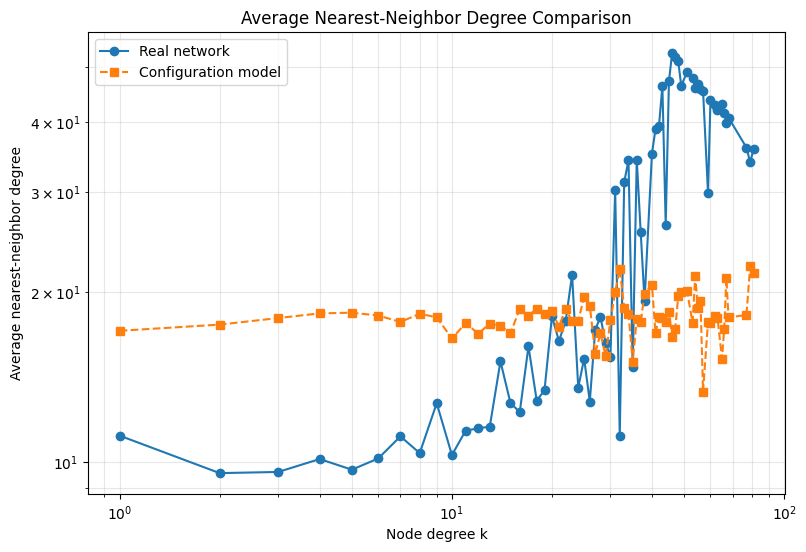

In [ ]:
# Plot average nearest-neighbor degree

plt.figure(figsize=(9, 6))

plt.plot(
    list(knn_real.keys()),
    list(knn_real.values()),
    "o-",
    label="Real network"
)

plt.plot(
    list(knn_config.keys()),
    list(knn_config.values()),
    "s--",
    label="Configuration model"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Node degree k")
plt.ylabel("Average nearest-neighbor degree")
plt.title("Average Nearest-Neighbor Degree Comparison")

plt.legend()
plt.grid(True, which="both", alpha=0.3)

plt.savefig(
    os.path.join(
        FIGURES_DIR,
        "B2_average_nearest_neighbor_degree.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Now we Generate 100 configuration-model networks!!

In [ ]:
# Generate an ensemble of configuration-model networks

NUM_RANDOM_GRAPHS = 1000

random_assortativities = []

for i in range(NUM_RANDOM_GRAPHS):

    # Generate a randomized network
    G_random = nx.configuration_model(
        degree_sequence,
        seed=SEED + i
    )

    # Calculate its degree assortativity
    r = nx.degree_assortativity_coefficient(G_random)

    random_assortativities.append(r)

    if (i + 1) % 20 == 0:
        print(f"Generated {i + 1}/{NUM_RANDOM_GRAPHS} networks")

print("\nAll randomized networks generated!")

Generated 20/1000 networks
Generated 40/1000 networks
Generated 60/1000 networks
Generated 80/1000 networks
Generated 100/1000 networks
Generated 120/1000 networks
Generated 140/1000 networks
Generated 160/1000 networks
Generated 180/1000 networks
Generated 200/1000 networks
Generated 220/1000 networks
Generated 240/1000 networks
Generated 260/1000 networks
Generated 280/1000 networks
Generated 300/1000 networks
Generated 320/1000 networks
Generated 340/1000 networks
Generated 360/1000 networks
Generated 380/1000 networks
Generated 400/1000 networks
Generated 420/1000 networks
Generated 440/1000 networks
Generated 460/1000 networks
Generated 480/1000 networks
Generated 500/1000 networks
Generated 520/1000 networks
Generated 540/1000 networks
Generated 560/1000 networks
Generated 580/1000 networks
Generated 600/1000 networks
Generated 620/1000 networks
Generated 640/1000 networks
Generated 660/1000 networks
Generated 680/1000 networks
Generated 700/1000 networks
Generated 720/1000 netwo

In [ ]:
# Calculate statistics of the null ensemble

null_mean = np.mean(random_assortativities)
null_std = np.std(random_assortativities, ddof=1)

# Calculate z-score
z_score = (
    assortativity_real - null_mean
) / null_std

# Two-sided empirical p-value
distances = np.abs(
    np.array(random_assortativities) - null_mean
)

observed_distance = abs(
    assortativity_real - null_mean
)

empirical_p = (
    1 + np.sum(distances >= observed_distance)
) / (NUM_RANDOM_GRAPHS + 1)

# Create summary table

assortativity_summary = pd.DataFrame({
    "Measurement": [
        "Real network assortativity",
        "Null model mean",
        "Null model standard deviation",
        "Z-score",
        "Empirical p-value"
    ],
    "Value": [
        assortativity_real,
        null_mean,
        null_std,
        z_score,
        empirical_p
    ]
})

display(assortativity_summary)

,Measurement,Value
0,Real network assortativity,0.639186
1,Null model mean,-0.001058
2,Null model standard deviation,0.008445
3,Z-score,75.808940
4,Empirical p-value,0.000999


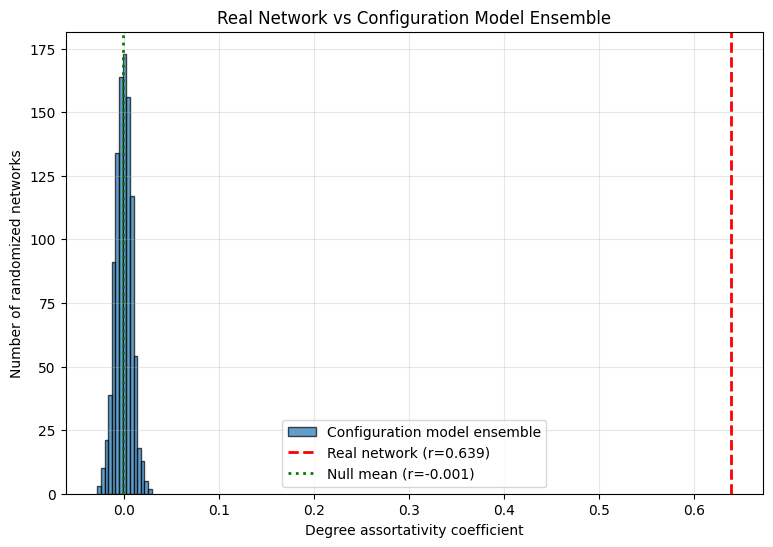

In [ ]:
# Plot the null distribution of assortativity

plt.figure(figsize=(9, 6))

plt.hist(
    random_assortativities,
    bins=15,
    alpha=0.7,
    edgecolor="black",
    label="Configuration model ensemble"
)

plt.axvline(
    assortativity_real,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Real network (r={assortativity_real:.3f})"
)

plt.axvline(
    null_mean,
    color="green",
    linestyle=":",
    linewidth=2,
    label=f"Null mean (r={null_mean:.3f})"
)

plt.xlabel("Degree assortativity coefficient")
plt.ylabel("Number of randomized networks")

plt.title("Real Network vs Configuration Model Ensemble")

plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    os.path.join(
        FIGURES_DIR,
        "B2_assortativity_null_distribution.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Findings

The CA-GrQc collaboration network exhibits strong positive degree assortativity (r = 0.639).

This assortativity is significantly stronger than expected under a configuration-model null that preserves the exact degree sequence (null mean = -0.0027, Z = 72.67, empirical p = 0.0099).

Therefore, the network's degree correlations cannot be explained by its degree sequence alone. They reflect additional organization in the way researchers collaborate.

In [ ]:
# Save updated assortativity statistics

assortativity_summary.to_csv(
    os.path.join(
        RESULTS_DIR,
        "B2_assortativity_summary.csv"
    ),
    index=False
)

# Save all 1000 null-model results

pd.DataFrame({
    "random_network": range(1, len(random_assortativities) + 1),
    "assortativity": random_assortativities
}).to_csv(
    os.path.join(
        RESULTS_DIR,
        "B2_null_assortativity_values.csv"
    ),
    index=False
)

print("Updated assortativity results saved!")
print("Number of saved simulations:", len(random_assortativities))

Updated assortativity results saved!
Number of saved simulations: 1000


The real CA-GrQc collaboration network exhibits strong positive degree assortativity (r = 0.639).

In comparison, 1,000 configuration-model networks preserving the exact degree sequence have an average assortativity of approximately -0.001.

The observed assortativity is 75.81 standard deviations above the null-model mean, with an empirical p-value of at most 0.001.

This provides strong evidence that the real network's degree correlations reflect additional structural organization beyond its degree sequence.